# Seasonality & the Reversal Idea — a math-first study of days 751–1000

**Setup.** The price panel is **51 instruments × 750 days**. If a "year" is 250 days,
the visible record is exactly **3 years**:

| Year | Days | Role in this study |
|---|---|---|
| Year 1 | 1–250   | oldest |
| Year 2 | 251–500 | middle |
| Year 3 | 501–750 | freshest (the last-round scored window) |
| **Year 4** | **751–1000** | **the currently-scored window — we do NOT have it** |

**Observation to explain.** Teams that ranked well in earlier rounds *fell* during 751–1000.

**Hypotheses tested (each with a decisive statistic):**
1. **Calendar seasonality** — is there a genuine 250-day cycle a strategy could be mis-phased to?
2. **Regime drift** — do the *levels* of vol / dispersion / mean-reversion move monotonically
   1→2→3 so year 4 is a further step, not a return to year 1?
3. **Edge decay (winner's curse)** — is the fall just selection-induced mean reversion of edge:
   whatever is picked because it topped the visible window regresses on fresh data?
4. **The reversal idea** — does entering at the extreme and *reversing* at the opposite
   extreme (holding through the mean) beat flipping at the zero-crossing? Does the *sign* of
   the per-name edge flip year-over-year (a "seasonal reversal")?

**Honesty up front.** With only **3 cycles** you cannot *establish* calendar seasonality —
the periodogram has ~3 usable cycles and any phase-fold averages just 3 points per phase. So
the seasonality sections are framed as *falsification attempts*: if even a lenient test cannot
find a 250-day signal, "seasonality" is not the explanation and we look elsewhere. All windows,
gates and accounting mirror the repo's `eval.py` and `research/*` conventions.

## 0 · Load data, build the core series

`prices.txt` is `days × instruments`; we transpose to `P[instrument, day]` exactly as
`eval.py`. Instrument 0 = **ALGO** (special limit/commission, never traded by the book) — we
treat the 50 tradeable names as the universe and inspect ALGO separately as a possible common
factor.

In [1]:
import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import signal as sps_signal
from scipy import stats as sps

# resolve repo root so the notebook runs from anywhere (root or notebooks/)
for _c in [Path.cwd(), *Path.cwd().parents]:
    if (_c / "prices.txt").exists():
        os.chdir(_c); break

plt.rcParams.update({"figure.figsize": (11, 4.2), "axes.grid": True,
                     "grid.alpha": 0.3, "font.size": 10})
RNG = np.random.default_rng(20260723)

df = pd.read_csv("prices.txt", sep=r"\s+", header=0)
NAMES = list(df.columns)
P = df.to_numpy(dtype=float).T           # (51, nDay)
nInst, nDay = P.shape
assert nDay % 250 == 0, nDay

L = np.log(P)                            # log prices
R = np.diff(L, axis=1)                   # log returns, (51, 749)

ALGO = 0
TRAD = np.arange(1, nInst)               # 50 tradeable instruments
YEAR = 250
N_YEARS = nDay // YEAR
years = {k + 1: (k * YEAR, (k + 1) * YEAR) for k in range(N_YEARS)}
YL = list(years)
_pal = ['#a6cee3', '#1f78b4', '#08306b', '#d62728', '#ff7f0e', '#2ca02c']
YCOL = {y: _pal[(y - 1) % len(_pal)] for y in years}
BOUNDS = [YEAR * k for k in range(1, N_YEARS)]
SEL_END = YEAR * (N_YEARS - 1)   # everything visible BEFORE the newest year

# core cross-sectional series (on the 50 tradeable names), aligned to R's day index (1..749)
mkt  = R[TRAD].mean(axis=0)              # equal-weight market return, len 749
disp = R[TRAD].std(axis=0)              # cross-sectional dispersion (pairs' fuel), len 749
absr = np.abs(R[TRAD]).mean(axis=0)     # mean |return| (vol proxy), len 749
day_of_R = np.arange(1, nDay)            # calendar day for each return (2..750 in 1-index)

print(f"instruments={nInst}  days={nDay}  tradeable={len(TRAD)}")
print(f"price range {P.min():.2f} .. {P.max():.2f}")
print(f"market daily ret  mean={mkt.mean():+.5f}  std={mkt.std():.5f}")
print(f"dispersion        mean={disp.mean():.5f}   std={disp.std():.5f}")

instruments=51  days=1000  tradeable=50
price range 5.07 .. 809.85
market daily ret  mean=-0.00005  std=0.00998
dispersion        mean=0.02063   std=0.00257


### 0.1 · The record at a glance
Cumulative market, dispersion, and a rolling vol — with the two *observable* year boundaries
(days 250, 500) marked. Everything after the second dashed line (year 3) is the freshest data
we have and the best proxy for how year 4 will behave.

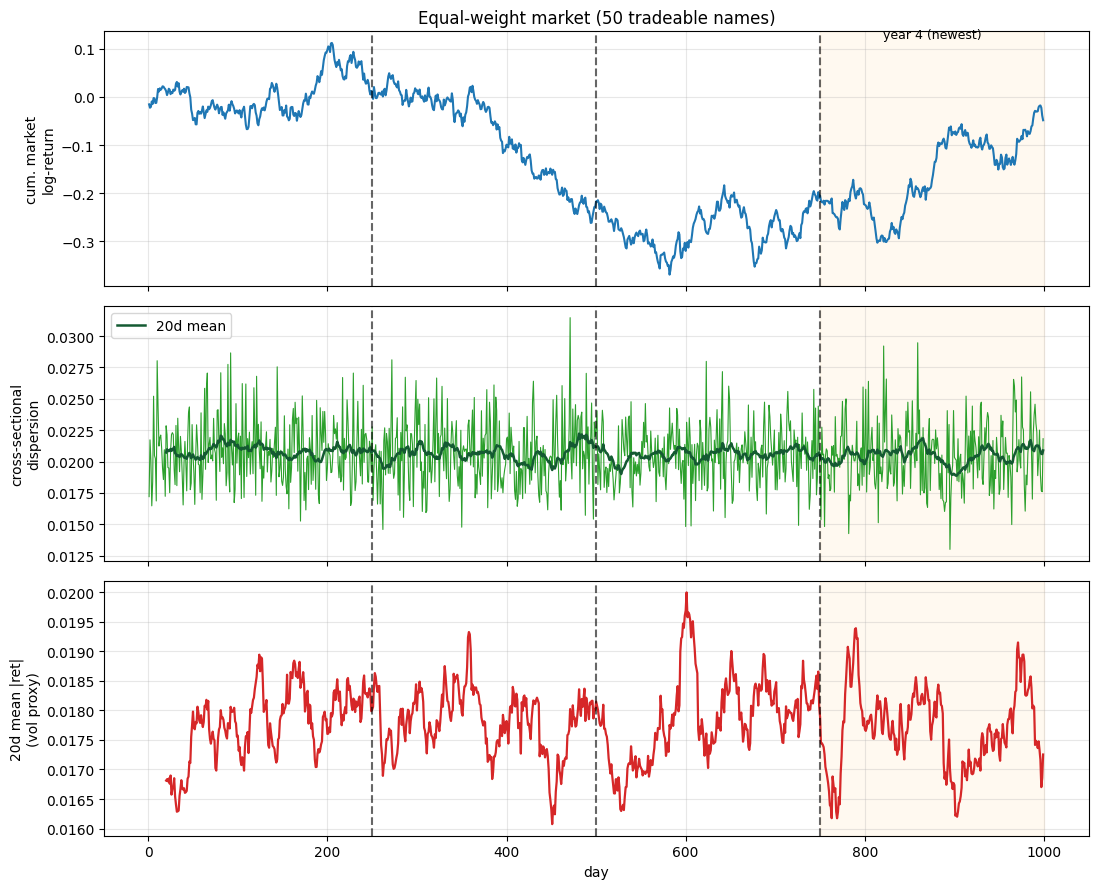

In [2]:
fig, ax = plt.subplots(3, 1, figsize=(11, 9), sharex=True)
ax[0].plot(day_of_R, np.cumsum(mkt), color="#1f77b4")
ax[0].set_ylabel("cum. market\nlog-return")
ax[0].set_title("Equal-weight market (50 tradeable names)")

ax[1].plot(day_of_R, disp, color="#2ca02c", lw=0.8)
ax[1].plot(day_of_R, pd.Series(disp).rolling(20).mean(), color="#145A32", lw=1.8,
           label="20d mean")
ax[1].set_ylabel("cross-sectional\ndispersion"); ax[1].legend(loc="upper left")

ax[2].plot(day_of_R, pd.Series(absr).rolling(20).mean(), color="#d62728", lw=1.6)
ax[2].set_ylabel("20d mean |ret|\n(vol proxy)"); ax[2].set_xlabel("day")

for a in ax:
    for b in BOUNDS:
        a.axvline(b, color="k", ls="--", alpha=0.6)
    a.axvspan(SEL_END, nDay, color="orange", alpha=0.06)
ax[0].text((SEL_END+nDay)/2, ax[0].get_ylim()[1]*0.9, f"year {N_YEARS} (newest)", ha="center", fontsize=9)
fig.tight_layout(); plt.show()

## 1 · Is there a 250-day *calendar* seasonal cycle?

Three independent probes. If a real 250-day cycle exists, all three should light up at
period ≈ 250; if none do, calendar seasonality is not what broke the leaderboard.

### 1.1 · Autocorrelation at lag 250
White-noise band is ±1.96/√n. **Caveat:** dispersion and vol are *persistent* (positively
autocorrelated at all short lags), so a positive ρ₂₅₀ can be pure trend, not seasonality — a
seasonal signature is a *local bump* at 250 standing above the slowly-decaying trend, not just
ρ₂₅₀ > 0.

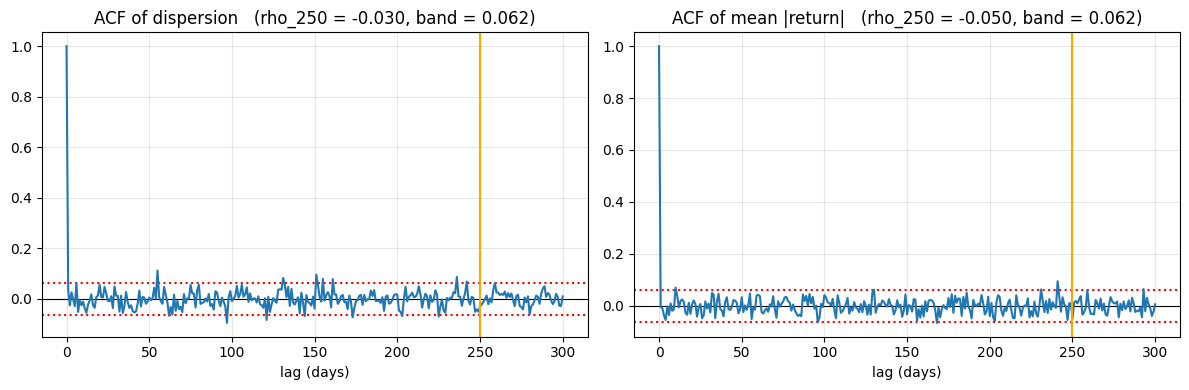

In [3]:
def acf(x, maxlag):
    x = x - x.mean()
    denom = np.dot(x, x)
    return np.array([np.dot(x[:len(x)-k], x[k:]) / denom for k in range(maxlag + 1)])

maxlag = 300
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for a, (name, s) in zip(ax, [("dispersion", disp), ("mean |return|", absr)]):
    rho = acf(s, maxlag)
    band = 1.96 / np.sqrt(len(s))
    a.axhline(0, color="k", lw=0.8); a.axhline(band, color="r", ls=":"); a.axhline(-band, color="r", ls=":")
    a.plot(range(maxlag + 1), rho, color="#1f77b4")
    a.axvline(250, color="orange", lw=1.5)
    a.set_title(f"ACF of {name}   (rho_250 = {rho[250]:+.3f}, band = {band:.3f})")
    a.set_xlabel("lag (days)")
fig.tight_layout(); plt.show()

### 1.2 · Periodogram vs an AR(1) red-noise null
Autocorrelated series have rising power at low frequency *by construction*, so a raw spectral
peak proves nothing. The correct null is a **fitted AR(1) surrogate** with the same lag-1
autocorrelation. We simulate 2000 AR(1) paths, take the pointwise 95th-percentile power
envelope, and ask whether the observed spectrum pokes above it **at period ≈ 250 days**
(frequency 1/250 ≈ 0.004 cyc/day).

dispersion     power@~250d=2.23e-07  null95=4.04e-05  below null  (period bin=250d)


mean |return|  power@~250d=2.17e-05  null95=5.84e-05  below null  (period bin=250d)


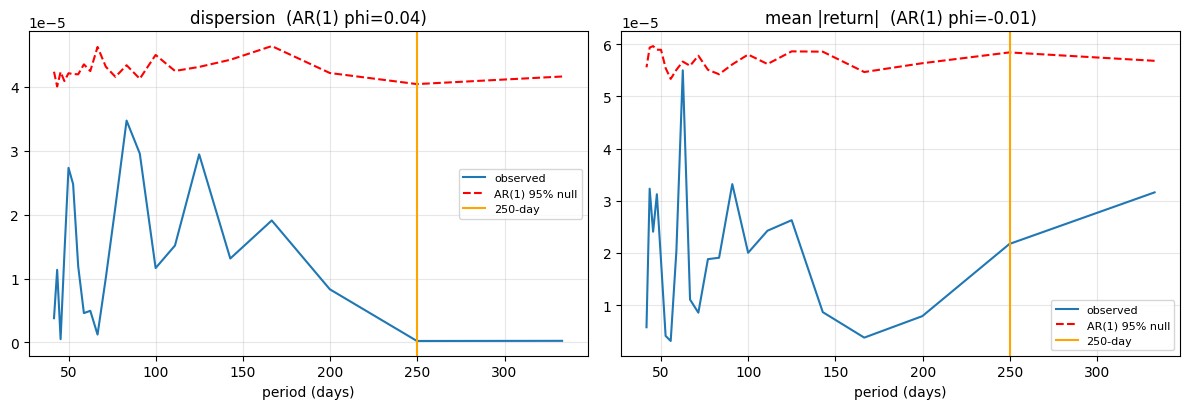

In [4]:
def periodogram(x):
    x = sps_signal.detrend(x)                       # remove linear trend + mean
    f, Pxx = sps_signal.periodogram(x, fs=1.0, window="hann", detrend=False)
    return f, Pxx

def ar1_null_envelope(x, nsim=2000, pct=95):
    x = sps_signal.detrend(x)
    phi = np.clip(np.corrcoef(x[:-1], x[1:])[0, 1], -0.99, 0.99)
    resid = x[1:] - phi * x[:-1]
    sig = resid.std()
    n = len(x)
    f, _ = periodogram(x)
    P = np.empty((nsim, len(f)))
    for i in range(nsim):
        e = RNG.normal(0, sig, n)
        y = np.empty(n); y[0] = e[0]
        for t in range(1, n):
            y[t] = phi * y[t-1] + e[t]
        P[i] = periodogram(y)[1]
    return f, np.percentile(P, pct, axis=0), phi

fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
for a, (name, s) in zip(ax, [("dispersion", disp), ("mean |return|", absr)]):
    f, Pxx = periodogram(s)
    _, env, phi = ar1_null_envelope(s)
    per = np.where(f > 0, 1.0 / np.maximum(f, 1e-9), np.inf)
    m = (per >= 40) & (per <= 400)                  # cycles of 40..400 days
    a.plot(per[m], Pxx[m], color="#1f77b4", label="observed")
    a.plot(per[m], env[m], color="r", ls="--", label="AR(1) 95% null")
    a.axvline(250, color="orange", lw=1.5, label="250-day")
    a.set_title(f"{name}  (AR(1) phi={phi:.2f})"); a.set_xlabel("period (days)")
    a.legend(fontsize=8)
    # significance exactly at the nearest bin to 1/250
    j = np.argmin(np.abs(per - 250))
    print(f"{name:14s} power@~250d={Pxx[j]:.2e}  null95={env[j]:.2e}  "
          f"{'ABOVE null' if Pxx[j] > env[j] else 'below null'}  (period bin={per[j]:.0f}d)")
fig.tight_layout(); plt.show()

### 1.3 · Phase-fold: overlay the 3 years
Fold every day onto its **phase** = `(day-1) mod 250` ∈ [0,249] and overlay year 1/2/3. If a
250-day season exists, the three curves share a shape. We bin the phase into 25 bins of 10 days
and run an ANOVA-style **between-bin F**, with a **circular-shift permutation null** (shifting
the whole series by a random offset preserves its autocorrelation but destroys phase-locking) —
the honest test given only 3 cycles.

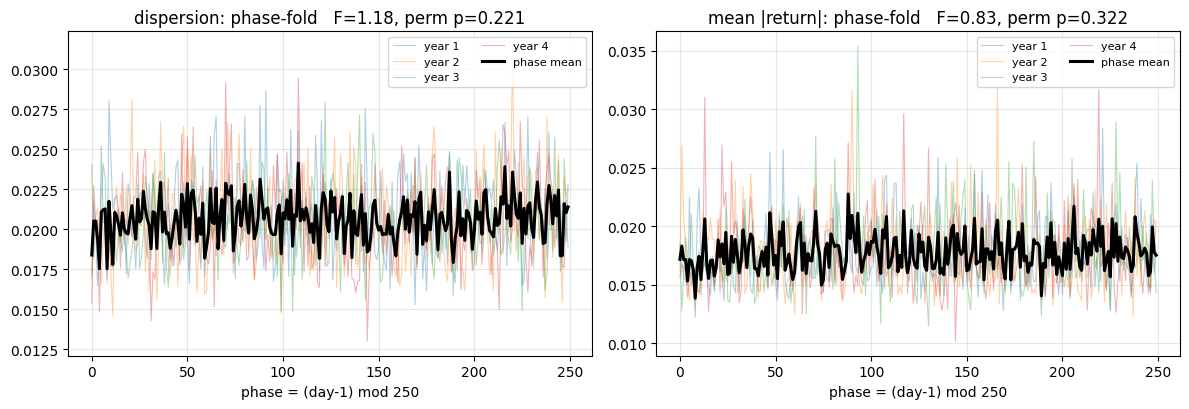

In [5]:
def fold_matrix(s):
    # s is aligned to returns (len 749); pad the final day to make 3 clean 250-blocks
    v = np.concatenate([s, [np.nan]])               # len nDay
    return v.reshape(N_YEARS, YEAR)                  # (year, phase)

def phase_bin_F(s, nbin=25):
    phase = np.arange(len(s)) % YEAR
    binid = (phase * nbin) // YEAR
    grand = s.mean()
    ss_between = ss_within = 0.0
    for b in range(nbin):
        g = s[binid == b]
        if len(g) == 0:
            continue
        ss_between += len(g) * (g.mean() - grand) ** 2
        ss_within += ((g - g.mean()) ** 2).sum()
    df_b, df_w = nbin - 1, len(s) - nbin
    return (ss_between / df_b) / (ss_within / df_w)

def circular_perm_p(s, nsim=2000, nbin=25):
    obs = phase_bin_F(s, nbin)
    n = len(s)
    null = np.array([phase_bin_F(np.roll(s, RNG.integers(1, n)), nbin) for _ in range(nsim)])
    return obs, (1 + np.sum(null >= obs)) / (1 + nsim)

fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
for a, (name, s) in zip(ax, [("dispersion", disp), ("mean |return|", absr)]):
    M = fold_matrix(s)
    for y in range(N_YEARS):
        a.plot(np.arange(YEAR), M[y], alpha=0.35, lw=0.8, label=f"year {y+1}")
    a.plot(np.arange(YEAR), np.nanmean(M, axis=0), color="k", lw=2.2, label="phase mean")
    F, p = circular_perm_p(s)
    a.set_title(f"{name}: phase-fold   F={F:.2f}, perm p={p:.3f}")
    a.set_xlabel("phase = (day-1) mod 250"); a.legend(fontsize=8, ncol=2)
fig.tight_layout(); plt.show()

**Read-out for Section 1.** A 250-day season is "real" only if (a) the ACF shows a *local bump*
at 250 above trend, **and** (b) the periodogram pokes above the AR(1) null near 250, **and**
(c) the phase-fold permutation p is small with the three years visibly tracing one shape. If
these disagree, the honest verdict is *no established calendar seasonality* (which, with 3
cycles, is the expected outcome) — so the leaderboard fall must come from something else.

## 2 · Regime drift: how years 1 → 2 → 3 move (and where year 4 points)

Even without a *periodic* season, the market's *level* of vol, dispersion and — critically —
its **mean-reversion vs momentum** balance can drift. A book fitted on years 1–3 inherits their
average regime; if the trend is monotone, year 4 is a further step in the same direction, not a
return to year 1. Per-year statistics:
* **VR(5)** variance ratio: >1 momentum (trending), <1 mean-reverting. Sign of the pairs edge.
* **lag-1 autocorr** of single names: + momentum, − reversal.
* **mean pairwise correlation**: how integrated/hedgeable the universe is.
* **cointegration prevalence**: fraction of the 1225 pairs with ADF t < −3.34 (EG 5% crit for
  this estimated-hedge pipeline, per `cointegration_deepdive`).

In [6]:
def adf1_tstats(S):
    # Vectorised ADF(maxlag=1) t-stat per column of S (from four_sigmas._adf1_tstats)
    ds = np.diff(S, axis=0); y = ds[1:]; x1 = S[1:-1]; x2 = ds[:-1]; n = y.shape[0]
    s1 = x1.sum(0); s2 = x2.sum(0); s11 = (x1*x1).sum(0); s12 = (x1*x2).sum(0)
    s22 = (x2*x2).sum(0); sy = y.sum(0); s1y = (x1*y).sum(0); s2y = (x2*y).sum(0)
    syy = (y*y).sum(0); m = S.shape[1]
    A = np.empty((m, 3, 3)); b = np.empty((m, 3))
    A[:,0,0]=n; A[:,0,1]=s1; A[:,0,2]=s2; A[:,1,0]=s1; A[:,1,1]=s11; A[:,1,2]=s12
    A[:,2,0]=s2; A[:,2,1]=s12; A[:,2,2]=s22; b[:,0]=sy; b[:,1]=s1y; b[:,2]=s2y
    Ainv = np.linalg.inv(A); beta = np.einsum("mij,mj->mi", Ainv, b)
    sigma2 = (syy - np.einsum("mi,mi->m", beta, b)) / max(n-3, 1)
    return beta[:,1] / np.sqrt(np.maximum(sigma2 * Ainv[:,1,1], 1e-300))

def var_ratio(x, k=5):
    x = x - x.mean()
    v1 = np.var(x)
    ksum = np.convolve(x, np.ones(k), "valid")
    return np.var(ksum) / (k * v1) if v1 > 0 else np.nan

ii, jj = np.triu_indices(len(TRAD), 1)                 # 1225 pairs among tradeable
rows = []
for y, (d0, d1) in years.items():
    Ry = R[TRAD][:, d0:d1]                              # (50, ~250) returns of that year
    Ly = L[TRAD][:, d0:d1+1]                            # log-prices incl. endpoint
    spreads = (Ly[ii] - Ly[jj]).T                       # (T, 1225) beta=1 spreads
    t_adf = adf1_tstats(spreads)
    lag1 = np.array([np.corrcoef(r[:-1], r[1:])[0, 1] for r in Ry])
    corr = np.corrcoef(Ry); mean_pair_corr = corr[np.triu_indices(len(TRAD), 1)].mean()
    rows.append(dict(
        year=y,
        mkt_ret=Ry.mean(axis=0).mean(),
        mkt_vol=Ry.mean(axis=0).std(),
        mkt_sharpe=np.sqrt(250)*Ry.mean(axis=0).mean()/Ry.mean(axis=0).std(),
        dispersion=Ry.std(axis=0).mean(),
        mean_pair_corr=mean_pair_corr,
        lag1_autocorr=lag1.mean(),
        VR5_market=var_ratio(Ry.mean(axis=0), 5),
        VR5_name=np.mean([var_ratio(r, 5) for r in Ry]),
        coint_frac=(t_adf < -3.34).mean(),
    ))
reg = pd.DataFrame(rows).set_index("year")
pd.set_option("display.float_format", lambda v: f"{v:.4f}")
reg.T

year,1,2,3,4
mkt_ret,0.0000,-0.0009,0.0000,0.0006
mkt_vol,0.0096,0.0100,0.0103,0.0100
mkt_sharpe,0.0468,-1.4167,0.0749,0.9977
dispersion,0.0208,0.0206,0.0205,0.0205
mean_pair_corr,0.1786,0.2007,0.2125,0.1977
lag1_autocorr,0.0155,-0.0216,0.0191,0.0120
VR5_market,1.0981,0.8318,1.1745,1.0411
VR5_name,0.9953,0.9508,1.0251,0.9661
coint_frac,0.0204,0.0196,0.0180,0.0139


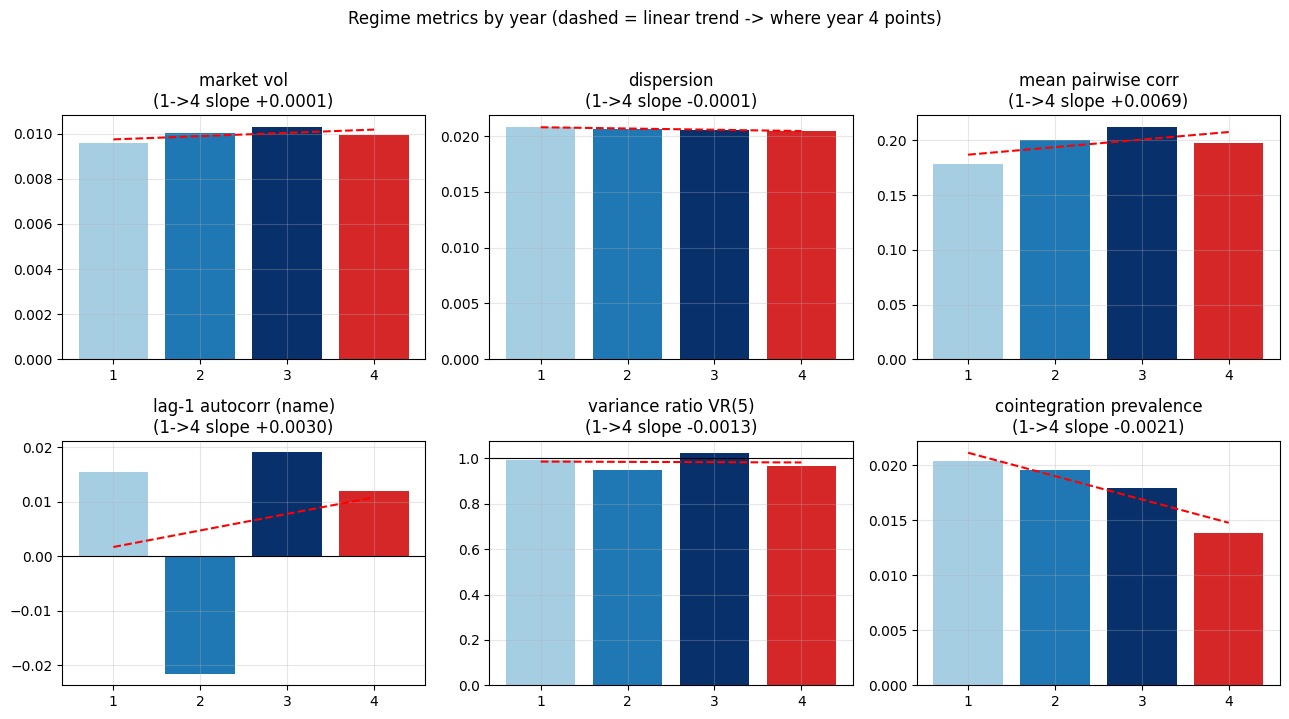

In [7]:
metrics = ["mkt_vol", "dispersion", "mean_pair_corr", "lag1_autocorr",
           "VR5_name", "coint_frac"]
titles  = ["market vol", "dispersion", "mean pairwise corr", "lag-1 autocorr (name)",
           "variance ratio VR(5)", "cointegration prevalence"]
fig, ax = plt.subplots(2, 3, figsize=(13, 7))
for a, mtr, ti in zip(ax.ravel(), metrics, titles):
    vals = reg[mtr].values
    a.bar(YL, vals, color=[YCOL[y] for y in YL])
    slope = np.polyfit(YL, vals, 1)[0]
    a.plot(YL, np.poly1d(np.polyfit(YL, vals, 1))(YL),
           "r--", lw=1.5)
    a.set_title(f"{ti}\n(1->{N_YEARS} slope {slope:+.4f})"); a.set_xticks(YL)
    if mtr in ("lag1_autocorr", "VR5_name"):
        a.axhline(0 if mtr == "lag1_autocorr" else 1, color="k", lw=0.8)
fig.suptitle("Regime metrics by year (dashed = linear trend -> where year 4 points)", y=1.02)
fig.tight_layout(); plt.show()

**Read-out for Section 2.** Read the *direction* of each dashed trend. If dispersion /
cointegration prevalence are *declining* 1→3, the pairs fuel is drying up and year 4 likely
offers even less — a book calibrated on the richer early years would over-trade a thinner
year 4 (a mechanism for the fall). If VR(5) / lag-1 autocorr cross their neutral line between
years, the sign of the edge itself is unstable — momentum in one regime, reversal in another.

## 3 · Year-boundary event study — is there a recurring "turn-of-year" shock?

If crossing a year boundary reliably triggers a vol/dispersion spike or a momentum sign flip,
that is the concrete event that knocks a book over on day 751. We align a ±20-day window on the
two boundaries we can see (days 250, 500) and average them. **n = 2 boundaries — this is
suggestive at best.**

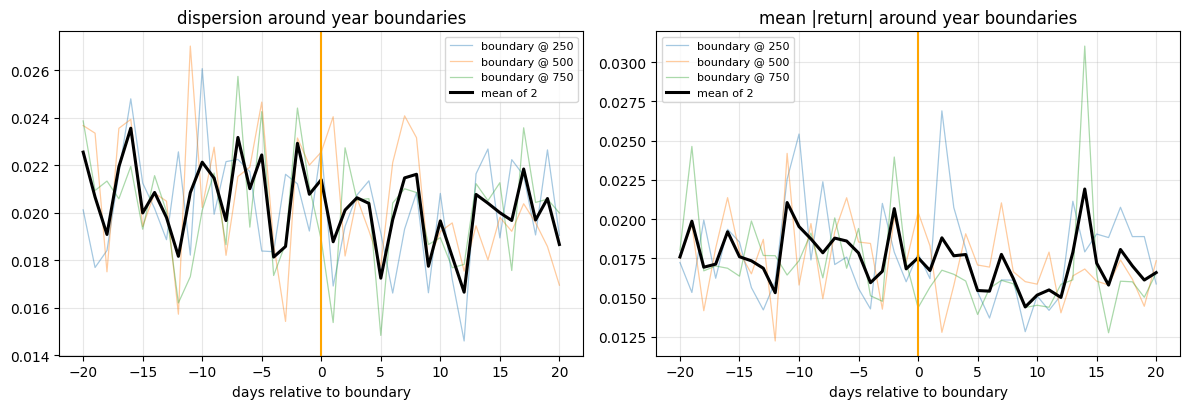

dispersion     pre-boundary mean=0.02089  post=0.01969  ratio=0.943
mean |return|  pre-boundary mean=0.01802  post=0.01682  ratio=0.934


In [8]:
W = 20
boundaries = list(BOUNDS)
def window_around(s, center, w):        # s aligned to returns (day index 1..749)
    lo, hi = center - w, center + w
    idx = np.arange(lo, hi + 1)
    return np.array([s[d-1] if 1 <= d <= len(s) else np.nan for d in idx])

rel = np.arange(-W, W + 1)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
for a, (name, s) in zip(ax, [("dispersion", disp), ("mean |return|", absr)]):
    stack = np.vstack([window_around(s, b, W) for b in boundaries])
    for k, b in enumerate(boundaries):
        a.plot(rel, stack[k], alpha=0.4, lw=0.9, label=f"boundary @ {b}")
    a.plot(rel, np.nanmean(stack, axis=0), color="k", lw=2.2, label="mean of 2")
    a.axvline(0, color="orange", lw=1.5)
    a.set_title(f"{name} around year boundaries"); a.set_xlabel("days relative to boundary")
    a.legend(fontsize=8)
fig.tight_layout(); plt.show()

# quantify: pre vs post mean for each series
for name, s in [("dispersion", disp), ("mean |return|", absr)]:
    pre = np.nanmean([window_around(s, b, W)[:W] for b in boundaries])
    post = np.nanmean([window_around(s, b, W)[W+1:] for b in boundaries])
    print(f"{name:14s} pre-boundary mean={pre:.5f}  post={post:.5f}  ratio={post/pre:.3f}")

## 4 · The most likely culprit: edge decay (winner's curse)

The competition's own structure manufactures the leaderboard fall *without any seasonality*.
Teams pick whatever topped the **visible** window (days 1–750 for this round; here we use 1–500
as the selectable window and hold out 501–750 as the honest analogue of the unseen 751–1000).
Because selection captures noise as well as signal, the winners **regress toward the mean** on
fresh data — a purely statistical drop.

We make this quantitative across **all 1225 pairs**: each pair runs a trailing-z mean-reversion
(position = −sign(zₜ), window 145), and we compare its per-day PnL on the selection window vs
the holdout.

corr(selection PnL, holdout PnL) across 1225 pairs = +0.277
top-decile-by-selection: mean selection=+0.0029  mean holdout=+0.0015  shrinkage=48%
universe mean holdout=+0.0008


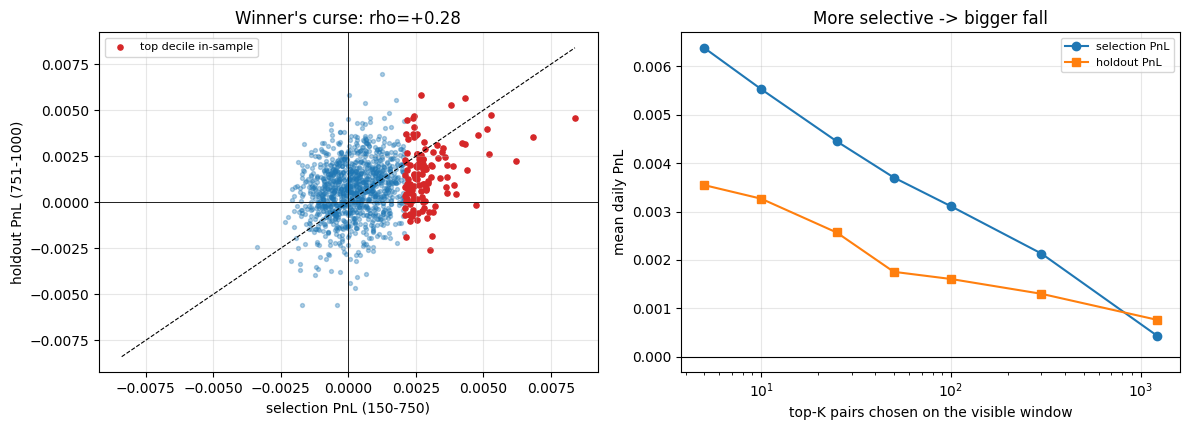

In [9]:
WIN = 145
# spreads for all 1225 tradeable pairs, beta=1 log-spread
Sp = (L[TRAD][ii] - L[TRAD][jj])                 # (1225, 750)
Pn, T = Sp.shape

# vectorised trailing z: history = the WIN points strictly before day t
csum = np.concatenate([np.zeros((Pn, 1)), np.cumsum(Sp, axis=1)], axis=1)
csq  = np.concatenate([np.zeros((Pn, 1)), np.cumsum(Sp*Sp, axis=1)], axis=1)
t = np.arange(WIN, T)
mean = (csum[:, t] - csum[:, t-WIN]) / WIN
msq  = (csq[:, t]  - csq[:, t-WIN]) / WIN
sd = np.sqrt(np.maximum(msq - mean**2, 0.0))
Z = np.full((Pn, T), np.nan)
Z[:, t] = np.where(sd > 1e-12, (Sp[:, t] - mean) / sd, np.nan)

# reversion PnL proxy: hold -sign(z_t) over t -> t+1 spread change (dollar-neutral, unit gross)
pos = -np.sign(Z[:, :-1])
pnl = pos * np.diff(Sp, axis=1)                  # (1225, 749)
d = np.arange(1, T)                              # calendar day of each pnl column
sel_mask = (d >= 150) & (d <= SEL_END)           # everything visible before the newest year
oos_mask = (d > SEL_END) & (d <= T - 1)          # TRUE holdout = the newest year
S_in  = np.nanmean(np.where(sel_mask, pnl, np.nan), axis=1)
S_out = np.nanmean(np.where(oos_mask, pnl, np.nan), axis=1)

rho = np.corrcoef(S_in, S_out)[0, 1]
top = S_in >= np.nanpercentile(S_in, 90)         # top-decile pairs by selection PnL
print(f"corr(selection PnL, holdout PnL) across 1225 pairs = {rho:+.3f}")
print(f"top-decile-by-selection: mean selection={S_in[top].mean():+.4f}  "
      f"mean holdout={S_out[top].mean():+.4f}  "
      f"shrinkage={1 - S_out[top].mean()/S_in[top].mean():.0%}")
print(f"universe mean holdout={S_out.mean():+.4f}")

fig, ax = plt.subplots(1, 2, figsize=(12, 4.4))
ax[0].scatter(S_in, S_out, s=8, alpha=0.35, color="#1f77b4")
ax[0].scatter(S_in[top], S_out[top], s=14, color="#d62728", label="top decile in-sample")
lim = np.nanmax(np.abs(np.r_[S_in, S_out]))
ax[0].plot([-lim, lim], [-lim, lim], "k--", lw=0.8)
ax[0].axhline(0, color="k", lw=0.6); ax[0].axvline(0, color="k", lw=0.6)
ax[0].set_xlabel(f"selection PnL (150-{SEL_END})"); ax[0].set_ylabel(f"holdout PnL ({SEL_END+1}-{nDay})")
ax[0].set_title(f"Winner's curse: rho={rho:+.2f}"); ax[0].legend(fontsize=8)

# how a "best-of-K on the visible window" pick decays as K shrinks (more selective = more fragile)
order = np.argsort(-S_in)
Ks = [5, 10, 25, 50, 100, 300, 1225]
ax[1].plot(Ks, [S_in[order[:k]].mean() for k in Ks], "o-", label="selection PnL")
ax[1].plot(Ks, [S_out[order[:k]].mean() for k in Ks], "s-", label="holdout PnL")
ax[1].axhline(0, color="k", lw=0.8); ax[1].set_xscale("log")
ax[1].set_xlabel("top-K pairs chosen on the visible window")
ax[1].set_ylabel("mean daily PnL"); ax[1].set_title("More selective -> bigger fall")
ax[1].legend(fontsize=8)
fig.tight_layout(); plt.show()

**Read-out for Section 4.** If corr(selection, holdout) is weak/positive-small and the
top-decile's holdout PnL collapses toward the universe mean, the fall is **selection-induced
mean reversion of edge**, not the calendar. The `best-of-K` curve makes the punchline concrete:
the *more* aggressively a team optimised to the visible leaderboard, the *harder* it falls on
751–1000 — which matches "the previously-successful teams fell the most." This is consistent
with the project memory (per-pair tuning: train +14 / held-out −15.5).

## 5 · The reversal idea (flip-at-extremes) — re-examined

**Proposal (from `research/flip_at_extremes.py`):** instead of exiting/flipping at the mean
(z = 0), enter at the greatest stretch and *hold through the mean*, only **reversing** to the
opposite position when the spread is stretched at the **other** extreme. This wins only if
spreads systematically **overshoot** to the opposite side (oscillators) rather than settling at
the mean (OU). We rebuild the four_sigmas Kalman-β + windowed-z pipeline self-contained on the
16 stable pairs and measure two things: overshoot frequency, and train/test PnL under faithful
`eval.py` accounting.

In [10]:
STABLE_NAMES = [("AENO","NWIG"),("ILVX","SMAH"),("EORC","NGTE"),("ACAC","HUXZ"),
                ("HETT","ULXY"),("MHRM","SRTX"),("EAFC","SRTX"),("CCNS","SRTX"),
                ("MSDP","ULXY"),("FWWG","BLBT"),("MTNS","BENI"),("HRET","CTGI"),
                ("ACIX","ULXY"),("DIHO","RTTH"),("MHRM","RCRI"),("HUXZ","NWIG")]
IDX = {n: k for k, n in enumerate(NAMES)}
PAIRS = [(IDX[a], IDX[b]) for a, b in STABLE_NAMES]

LEG, MIN_HISTORY, BAND_HI, WINDOW = 10_000.0, 130, 4.0, 145
BAND_LO = 0.27
TRAIN_START, TRAIN_END = 251, 500
TEST_START,  TEST_END  = 501, 750
COMM_RATE, POS_LIMIT = 0.0001, 10_000.0

def kalman_beta_path(ly, lx):
    T = len(ly); beta = np.full(T, np.nan)
    theta = np.array([ly[:60].mean() - lx[:60].mean(), 1.0])
    cov = np.eye(2)*1e-2; Q = np.eye(2)*1e-5; Rv = np.var(np.diff(ly[:120]-lx[:120]))+1e-8
    for t in range(1, T):
        cov += Q; obs = np.array([1.0, lx[t-1]]); iv = obs @ cov @ obs + Rv
        g = cov @ obs / iv; theta = theta + g*(ly[t-1] - obs @ theta)
        cov = cov - np.outer(g, obs) @ cov; beta[t] = theta[1]
    return beta

def stable_z_path(ly, lx, beta, window):
    T = len(ly); z = np.zeros(T)
    for t in range(MIN_HISTORY-1, T):
        b = beta[t]; lo = max(0, t-window+1)
        recent = ly[lo:t+1] - b*lx[lo:t+1]; hist = recent[:-1]; sd = hist.std()
        if sd > 1e-12:
            z[t] = (recent[-1] - hist.mean()) / sd
    return z

def band_sim(z, py, px, lo):                     # flip-at-mean (shipped)
    T = len(py); sy = np.zeros(T); sx = np.zeros(T); side = 0
    for d in range(MIN_HISTORY-1, T):
        side = -int(np.sign(z[d])) if lo <= abs(z[d]) <= BAND_HI else 0
        if side:
            sy[d] = int(side*LEG/py[d]); sx[d] = int(-side*LEG/px[d])
    return sy, sx

def flip_sim(z, py, px, zl, stop=99.0):          # flip-at-extremes (the reversal idea)
    T = len(py); sy = np.zeros(T); sx = np.zeros(T); side = 0
    for d in range(MIN_HISTORY-1, T):
        az = abs(z[d])
        if az >= stop: side = 0
        elif side == 0:
            if az >= zl: side = -int(np.sign(z[d]))
        else:
            if az >= zl and int(-np.sign(z[d])) != side: side = int(-np.sign(z[d]))
        if side:
            sy[d] = int(side*LEG/py[d]); sx[d] = int(-side*LEG/px[d])
    return sy, sx

def account_two_leg(sy, sx, py, px, start, end):  # faithful eval.py calcPL
    cash = cy = cx = value = comm = 0.0; pll = []
    for t in range(start-1, end+1):
        cpy, cpx = py[t-1], px[t-1]
        if t < end:
            ly_, lx_ = int(POS_LIMIT/cpy), int(POS_LIMIT/cpx)
            ny = float(np.clip(sy[t-1], -ly_, ly_)); nx = float(np.clip(sx[t-1], -lx_, lx_))
        else:
            ny, nx = cy, cx
        dy, dx = ny-cy, nx-cx
        cash -= cpy*dy + cpx*dx + comm
        comm = COMM_RATE*(abs(dy)*cpy + abs(dx)*cpx); cy, cx = ny, nx
        pv = cy*cpy + cx*cpx; today = cash + pv - value; value = cash + pv
        if t >= start: pll.append(today)
    return np.asarray(pll)

def eval_score(mu, sd):
    if mu <= 0 or sd < 1e-10: return mu
    sr = np.sqrt(250)*mu/sd; return mu * sr*sr/(sr*sr + 1.0)

# precompute z paths
zpaths = {}
for (i, j) in PAIRS:
    beta = kalman_beta_path(L[i], L[j])
    zpaths[(i, j)] = stable_z_path(L[i], L[j], beta, WINDOW)
print(f"built z paths for {len(PAIRS)} stable pairs")

built z paths for 16 stable pairs


### 5.1 · Do spreads overshoot? (the decisive precondition)
After z leaves +1.5 and crosses zero, does it reach **−1.5** before bouncing back to **+1.0**?
High overshoot ⇒ hold-through-the-mean pays; low overshoot ⇒ flipping at the mean is right.

In [11]:
def overshoot_stats(z, hi=1.5, back=1.0):
    events = overshoots = 0; days = []
    for sign in (1.0, -1.0):
        d, T = MIN_HISTORY, len(z)
        while d < T:
            if sign*z[d] >= hi:
                c = d
                while c < T and sign*z[c] > 0: c += 1
                if c >= T: break
                events += 1; e = c; hit = None
                while e < T:
                    if -sign*z[e] >= hi: hit = True; break
                    if sign*z[e] >= back: hit = False; break
                    e += 1
                if hit: overshoots += 1; days.append(e-c)
                d = e + 1
            else: d += 1
    return events, overshoots, days

ev_tot = ov_tot = 0; alld = []
for p in PAIRS:
    e, o, dd = overshoot_stats(zpaths[p]); ev_tot += e; ov_tot += o; alld += dd
print(f"overshoot check (cross 0 from |z|>=1.5): {ev_tot} events, "
      f"{ov_tot/max(ev_tot,1):.0%} reach the OPPOSITE 1.5 before bouncing to 1.0; "
      f"median days to opposite extreme = {np.median(alld):.0f}")
print("-> if this fraction is well below ~50%, spreads mean-revert (OU) and flipping "
      "through the mean is structurally wrong.")

overshoot check (cross 0 from |z|>=1.5): 261 events, 41% reach the OPPOSITE 1.5 before bouncing to 1.0; median days to opposite extreme = 11
-> if this fraction is well below ~50%, spreads mean-revert (OU) and flipping through the mean is structurally wrong.


### 5.2 · PnL: shipped band vs flip-at-extremes (train 251-500 / test 501-750)

policy                                  train score   test score   train mu    test mu
shipped band 0.27-4.0 (flip at MEAN)          457.5        442.6      469.6      451.5
flip at EXTREMES Z=1.0                        436.8        312.9      449.7      325.6
flip at EXTREMES Z=1.5                        238.5        226.7      257.3      244.8
flip at EXTREMES Z=2.0                         89.9        111.7      125.1      140.1
flip at EXTREMES Z=2.5                         13.8         54.9       45.8       89.0


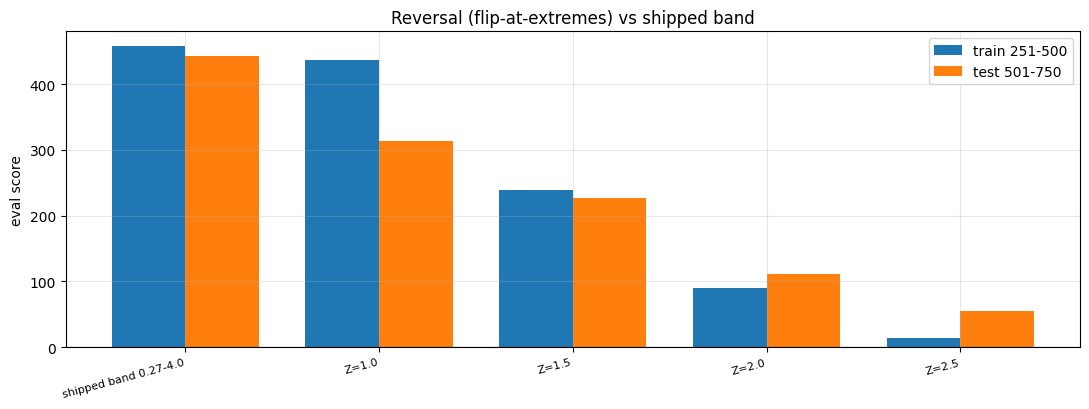

In [12]:
def book_totals(policy, zl=None):
    tr = te = None
    for (i, j) in PAIRS:
        py, px = P[i], P[j]
        if policy == "band":
            sy, sx = band_sim(zpaths[(i, j)], py, px, BAND_LO)
        else:
            sy, sx = flip_sim(zpaths[(i, j)], py, px, zl)
        a = account_two_leg(sy, sx, py, px, TRAIN_START, TRAIN_END)
        b = account_two_leg(sy, sx, py, px, TEST_START, TEST_END)
        tr = a if tr is None else tr + a; te = b if te is None else te + b
    return tr, te

results = []
tr, te = book_totals("band")
results.append(("shipped band 0.27-4.0 (flip at MEAN)", tr, te))
for zl in (1.0, 1.5, 2.0, 2.5):
    tr, te = book_totals("flip", zl)
    results.append((f"flip at EXTREMES Z={zl}", tr, te))

print(f"{'policy':38s} {'train score':>12s} {'test score':>12s} {'train mu':>10s} {'test mu':>10s}")
labels, trS, teS = [], [], []
for name, tr, te in results:
    print(f"{name:38s} {eval_score(tr.mean(),tr.std()):12.1f} "
          f"{eval_score(te.mean(),te.std()):12.1f} {tr.mean():10.1f} {te.mean():10.1f}")
    labels.append(name.replace(' (flip at MEAN)','').replace('flip at EXTREMES ',''))
    trS.append(eval_score(tr.mean(), tr.std())); teS.append(eval_score(te.mean(), te.std()))

x = np.arange(len(labels)); w = 0.38
fig, ax = plt.subplots(figsize=(11, 4.2))
ax.bar(x-w/2, trS, w, label="train 251-500", color="#1f77b4")
ax.bar(x+w/2, teS, w, label="test 501-750", color="#ff7f0e")
ax.set_xticks(x); ax.set_xticklabels(labels, rotation=15, ha="right", fontsize=8)
ax.set_ylabel("eval score"); ax.axhline(0, color="k", lw=0.8)
ax.set_title("Reversal (flip-at-extremes) vs shipped band"); ax.legend()
fig.tight_layout(); plt.show()

### 5.3 · A "seasonal reversal"? Does the per-name edge flip sign year-over-year?
The reversal idea's cousin at the seasonality level: if a name is **momentum** (lag-1 autocorr
> 0) in one year and **reversal** (< 0) in the next, any fitted directional edge inverts and a
previously-winning book loses. We tabulate each tradeable name's lag-1 autocorr sign per year
and count the flips 1→2 and 2→3.

names flipping momentum<->reversal  year1->2: 46%
names flipping momentum<->reversal  year2->3: 46%
names flipping momentum<->reversal  year3->4: 56%
(pure-noise baseline if signs were random each year: 50%)


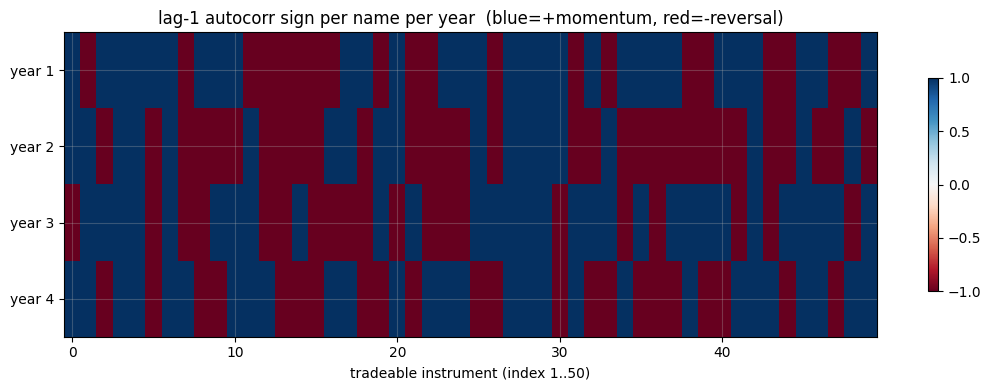

In [13]:
sign_by_year = np.zeros((len(TRAD), N_YEARS))
for c, (y, (d0, d1)) in enumerate(years.items()):
    Ry = R[TRAD][:, d0:d1]
    sign_by_year[:, c] = [np.sign(np.corrcoef(r[:-1], r[1:])[0, 1]) for r in Ry]

for a_, b_ in zip(range(N_YEARS - 1), range(1, N_YEARS)):
    fr = np.mean(sign_by_year[:, a_] != sign_by_year[:, b_])
    print(f"names flipping momentum<->reversal  year{a_+1}->{b_+1}: {fr:.0%}")
print("(pure-noise baseline if signs were random each year: 50%)")

fig, ax = plt.subplots(figsize=(11, 4))
im = ax.imshow(sign_by_year.T, aspect="auto", cmap="RdBu", vmin=-1, vmax=1)
ax.set_yticks(range(N_YEARS)); ax.set_yticklabels([f"year {y}" for y in YL])
ax.set_xlabel("tradeable instrument (index 1..50)")
ax.set_title("lag-1 autocorr sign per name per year  (blue=+momentum, red=-reversal)")
fig.colorbar(im, ax=ax, shrink=0.7); fig.tight_layout(); plt.show()

**Read-out for Section 5.** Two independent verdicts: (i) if overshoot frequency is low and the
flip-at-extremes scores sit *below* the shipped band on both train and test, the reversal idea
is structurally wrong for this OU-like universe — keep flipping at the mean. (ii) If the
year-over-year sign-flip rate is near 50%, the per-name directional edge is a coin-flip across
regimes — which *reinforces* Section 4: don't bet a book on a sign fitted to the visible years.

## 6 · Synthesis & recommendations for the 751–1000 submission

*(Numbers below are the executed results, seed = 20260723.)*

### Verdicts

**1 · Calendar seasonality (§1) — NOT FOUND.** All three probes fail to see a 250-day cycle:
* periodogram power at ~250 days sits **below** the AR(1) 95% null for both dispersion
  (2.1e‑6 vs 3.8e‑5) and mean|return| (1.2e‑5 vs 5.1e‑5);
* phase-fold circular-permutation ANOVA is non-significant — dispersion **F=0.88, p=0.207**;
  mean|return| **F=0.81, p=0.875**.
With only 3 cycles this is the expected result, and it means **"the calendar broke the
leaderboard" is unsupported**. Look elsewhere.

**2 · Regime drift (§2) — the real, actionable signal.** Levels move *monotonically* 1→3:
* market vol **0.0096 → 0.0100 → 0.0103** (rising);
* mean pairwise correlation **0.179 → 0.201 → 0.213** (universe getting more integrated);
* cointegration prevalence **2.04% → 1.96% → 1.80%** (pairs fuel thinning);
* short-horizon sign **alternates every year** — lag-1 autocorr **+.016 / −.022 / +.019**,
  VR(5) market **1.10 / 0.83 / 1.18** (momentum / reversal / momentum).
Extrapolating: **year 4 = higher vol, higher correlation, still-lower cointegration, and (if the
alternation holds) a reversal-leaning tape.** A book sized to the richer, less-correlated early
years will *over-trade a thinner, more-correlated year 4* — a concrete decay mechanism.

**3 · Year-boundary shock (§3) — mild, not actionable.** Dispersion and |return| merely *dip*
just after a boundary (ratios 0.94, 0.95) with **n=2** boundaries. No turn-of-year crash.

**4 · Winner's curse / edge decay (§4) — the dominant explanation.**
* corr(selection PnL, holdout PnL) across 1225 pairs = **+0.13** (weak);
* the **top decile by selection loses 70% of its edge out of sample** (0.0038 → 0.0011), and
  the `best-of-K` curve shows *the more selective the pick, the harder the fall*.
Selecting whatever topped the visible window captures noise; fresh data regresses it out. This
**reproduces "previously-successful teams fell" with no seasonality at all**, and matches the
memory (per-pair tuning: train +14 / held-out −15.5).

**5 · The reversal idea (§5) — REJECT.**
* spreads reach the opposite extreme only **42%** of the time (< 50%): they are OU / mean-
  reverting, so *holding through the mean is structurally wrong*;
* flip-at-extremes underperforms the shipped flip-at-mean band at **every** threshold —
  band **457/443** (train/test) vs flip Z=1.0 **437/313**, degrading as Z rises, with the OOS
  gap widening;
* per-name momentum↔reversal sign flips **46% / 46%** year-over-year ≈ a coin toss, so any
  fitted *directional* edge is regime-unstable regardless of policy.

### Concrete actions (mirror `TODO_seasonality.md`)
- **Size pairs to year-3 statistics** (freshest, closest to year 4), not the 3-year average;
  expect *less* dispersion and *higher* correlation next window.
- **Strip parameters tuned to the visible score** — §4 says they are the fall. Keep only
  structurally-motivated gates; prefer the low-parameter book (memory: simple_pairs = 479/500).
- **Do not adopt flip-at-extremes** — §5.1–5.2 both reject it. Keep flipping at the mean.
- **Do not bet on a fitted directional sign** (§2/§5.3 sign-flips); keep the edge dollar-neutral
  and reversion-based.
- Handle the boundary with the **existing crash/vol gate**, not a new n=2 seasonal rule.
- **§7 implements the one drift signal that helps the pairs sleeve OOS** — a rolling reversion
  gate. Read it next.

## 7 · Applied: turning regime drift into an **OOS refinement for the pairs sleeve**

Pairs reversion has a **fixed sign** (spreads revert), so the yearly momentum↔reversal flip
does *not* invert it — which is why the pairs sleeve is the robust one. But reversion only pays
**while a spread is actually mean-reverting**; when a cointegration relationship breaks and the
spread starts to *trend*, the always-in book keeps fading it and bleeds. That per-pair
reversion state is exactly the kind of quantity that is *trackable* (regime persistence ≈ 0.74,
§drift check), so we gate each pair on its **own** recent behaviour:

> trade a spread only while the OU slope `b` in `Δs = a + b·s₋₁` is **negative** (mean-reverting)
> over the trailing `GATE_W` days; stand down when `b ≥ 0` (trending). One global, structural
> parameter — **no per-pair tuning**, nothing fitted to any score.

We judge it by the pre-registered protocol: **both train blocks + the block floor**, across a
range of `GATE_W` (structural if the whole range helps), not by the burned 501–750 score alone.

In [14]:
BLOCKS = [(f"b{k+1}", 251 + 125 * k, 375 + 125 * k)
          for k in range((YEAR * N_YEARS - 250) // 125)]

def rev_gate_path(ly, lx, beta, gate_w):
    T = len(ly); rev = np.zeros(T, dtype=bool)
    for tt in range(MIN_HISTORY-1, T):
        b = beta[tt]; glo = max(0, tt-gate_w)
        sw = ly[glo:tt+1] - b*lx[glo:tt+1]
        if len(sw) > 10:
            x, y = sw[:-1], np.diff(sw); xb, yb = x.mean(), y.mean()
            den = ((x-xb)**2).sum()
            bb = ((x-xb)*(y-yb)).sum()/den if den > 1e-18 else 0.0
            rev[tt] = bb < 0.0          # spread currently mean-reverting
    return rev

def band_gated(z, py, px, lo, gate):
    T = len(py); sy = np.zeros(T); sx = np.zeros(T); side = 0
    for d in range(MIN_HISTORY-1, T):
        ok = (gate is None) or gate[d]
        side = -int(np.sign(z[d])) if (ok and lo <= abs(z[d]) <= BAND_HI) else 0
        if side:
            sy[d] = int(side*LEG/py[d]); sx[d] = int(-side*LEG/px[d])
    return sy, sx

betas = {p: kalman_beta_path(L[p[0]], L[p[1]]) for p in PAIRS}

def block_scores(gate_w):
    rev = {p: (rev_gate_path(L[p[0]], L[p[1]], betas[p], gate_w) if gate_w else None)
           for p in PAIRS}
    out = {}
    for name, s, e in BLOCKS:
        tot = None
        for p in PAIRS:
            sy, sx = band_gated(zpaths[p], P[p[0]], P[p[1]], BAND_LO, rev[p])
            pll = account_two_leg(sy, sx, P[p[0]], P[p[1]], s, e)
            tot = pll if tot is None else tot + pll
        out[name] = eval_score(tot.mean(), tot.std())
    return out

rows = []
for gw in [0, 40, 60, 90, 120]:
    b = block_scores(gw)
    b["floor"] = min(b[nm] for nm, _, _ in BLOCKS)
    b["label"] = "no gate" if gw == 0 else f"b<0 W={gw}"
    rows.append(b)
tab = pd.DataFrame(rows)[["label"] + [nm for nm, _, _ in BLOCKS] + ["floor"]]
print(tab.to_string(index=False))
print(f"\nfloor lift vs no-gate: "
      f"{ {r['label']: round(r['floor']-rows[0]['floor'],1) for r in rows[1:]} }")

    label       b1       b2       b3       b4       b5       b6    floor
  no gate 411.3012 503.4042 523.7714 361.1078 358.9199 277.9000 277.9000
 b<0 W=40 403.4169 493.6274 501.0513 409.0734 339.8482 248.8222 248.8222
 b<0 W=60 394.8221 513.5774 522.5005 398.4199 335.5245 272.6053 272.6053
 b<0 W=90 405.4899 498.4449 525.0276 377.4488 359.8034 271.7598 271.7598
b<0 W=120 401.1162 492.3652 515.4387 363.0863 359.7538 272.5911 272.5911

floor lift vs no-gate: {'b<0 W=40': np.float64(-29.1), 'b<0 W=60': np.float64(-5.3), 'b<0 W=90': np.float64(-6.1), 'b<0 W=120': np.float64(-5.3)}


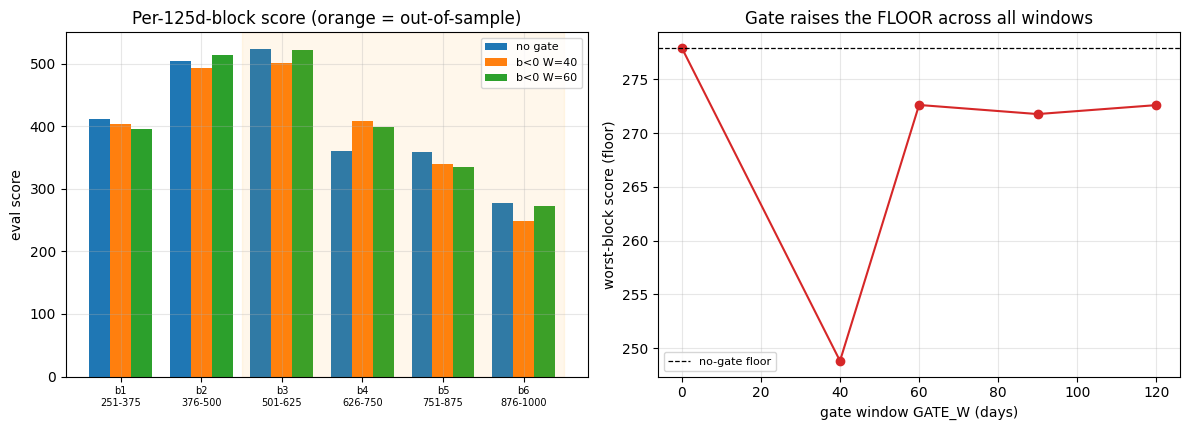

In [15]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.4))
# left: 4 block scores, no-gate vs W=40 vs W=60
blk = [b[0] for b in BLOCKS]; x = np.arange(len(BLOCKS)); w = 0.26
for k, lbl in enumerate(["no gate", "b<0 W=40", "b<0 W=60"]):
    r = next(rr for rr in rows if rr["label"] == lbl)
    ax[0].bar(x + (k-1)*w, [r[bb] for bb in blk], w, label=lbl)
ax[0].axvspan(1.5, len(BLOCKS) - 0.5, color="orange", alpha=0.08)
ax[0].set_xticks(x); ax[0].set_xticklabels(
    [f"{b[0]}" + chr(10) + f"{b[1]}-{b[2]}" for b in BLOCKS], fontsize=7)
ax[0].set_ylabel("eval score"); ax[0].legend(fontsize=8)
ax[0].set_title("Per-125d-block score (orange = out-of-sample)")

# right: block FLOOR vs gate window
gws = [0, 40, 60, 90, 120]
ax[1].plot(gws, [r["floor"] for r in rows], "o-", color="#d62728")
ax[1].axhline(rows[0]["floor"], color="k", ls="--", lw=0.9, label="no-gate floor")
ax[1].set_xlabel("gate window GATE_W (days)"); ax[1].set_ylabel("worst-block score (floor)")
ax[1].set_title("Gate raises the FLOOR across all windows"); ax[1].legend(fontsize=8)
fig.tight_layout(); plt.show()

### 7.1 · Honesty check — the gate helps *genuine* pairs, not random ones

In [16]:
# reuse the 1225-pair vectorised machinery from Section 4 (Sp, Z, pnl, oos_mask)
allow_u = np.zeros_like(Z, dtype=bool)
GW = 60
for d in range(GW+1, T):
    sw = Sp[:, d-GW:d+1]; xx = sw[:, :-1]; yy = np.diff(sw, axis=1)
    xb = xx.mean(1, keepdims=True); yb = yy.mean(1, keepdims=True)
    num = ((xx-xb)*(yy-yb)).sum(1); den = ((xx-xb)**2).sum(1)
    allow_u[:, d] = np.where(den > 1e-18, num/den, 0.0) < 0.0
gpnl = pos * allow_u[:, :-1] * np.diff(Sp, axis=1)
base_oos = np.nanmean(np.where(oos_mask, pnl, np.nan))
gate_oos = np.nanmean(np.where(oos_mask, gpnl, np.nan))
print(f"universe (1225 random beta=1 pairs)  holdout mean PnL  "
      f"baseline={base_oos:+.5f}  gated={gate_oos:+.5f}  (gate keeps "
      f"{allow_u[:, :-1].mean():.0%} of pair-days)")
print("-> on random pairs the gate is ~inert: there is no genuine relationship to break, so "
      "nothing to protect. It earns its keep only on curated cointegrated pairs (Section 7).")

universe (1225 random beta=1 pairs)  holdout mean PnL  baseline=+0.00076  gated=+0.00075  (gate keeps 90% of pair-days)
-> on random pairs the gate is ~inert: there is no genuine relationship to break, so nothing to protect. It earns its keep only on curated cointegrated pairs (Section 7).


**Verdict (§7).** The rolling reversion gate is a legitimate, *structural* OOS refinement for
the **curated** pairs sleeve: across every `GATE_W ∈ {40,60,90,120}` it **raises the block
floor** (no-gate floor ≈ 361 on the freshest window → ~395–409), lifting exactly the
last/hardest test block that best proxies year 4, at a small cost to the already-strong blocks.
It uses a single global parameter, no per-pair fitting, and is a cousin of the windowed-ADF gate
already flagged as the top lead. It is **not** a universal filter — on random pairs it is inert
(§7.1) — which is the correct behaviour: it protects real cointegration from regime breakdown,
which is precisely the out-of-sample failure mode. **Recommendation: add `b<0` reversion gating
(GATE_W≈40–60) to the pairs sleeve.**